In [24]:
import numpy as np
import h5py
import matplotlib.pyplot as pl
import scipy
import os
import sys

from os.path import join
from util import get_index_from_rxList
from reader import simulation_reader

fontsize = 18
labelsize = 16

In [25]:
fname_in = 'example/example-sim-NP_z_tx_5.0_buffer.h5'
print(os.path.isfile(fname_in))
sim_reader = simulation_reader(fname_hdf=fname_in)

True
65 65
(65, 3917) complex128


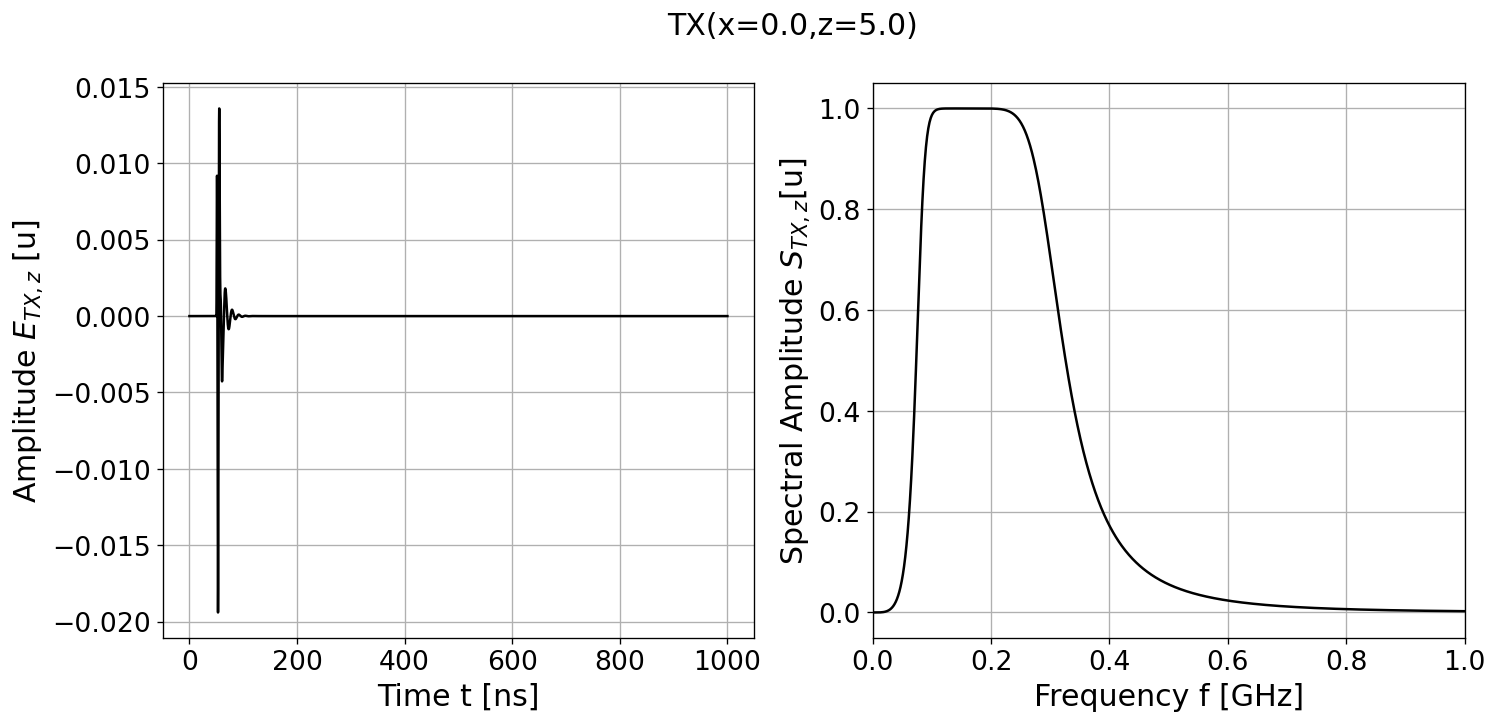

In [26]:
# Plot the TX Pulse
tx_pulse = sim_reader.txPulse
tspace_tx = sim_reader.tspace_tx

tx_spec = sim_reader.txSpectra
fspace_tx = sim_reader.fspace_tx

fig = pl.figure(figsize=(14,6),dpi=120)
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
ax_l = [ax1, ax2]
fig.suptitle(f'TX(x={sim_reader.sourceRange},z={sim_reader.sourceDepth})',fontsize=fontsize)
ax1.plot(tspace_tx, tx_pulse, c='k')
ax2.plot(fspace_tx, abs(tx_spec), c='k')

ax1.set_ylabel('Amplitude $E_{TX,z}$ [u]',fontsize=fontsize)
ax1.set_xlabel('Time t [ns]',fontsize=fontsize)

ax2.set_ylabel('Spectral Amplitude $S_{TX,z} $[u]',fontsize=fontsize)
ax2.set_xlabel('Frequency f [GHz]',fontsize=fontsize)
ax2.set_xlim(0, 1)

for i in range(len(ax_l)):
    ax_l[i].grid()
    ax_l[i].tick_params(axis='both',labelsize=labelsize)
pl.show()

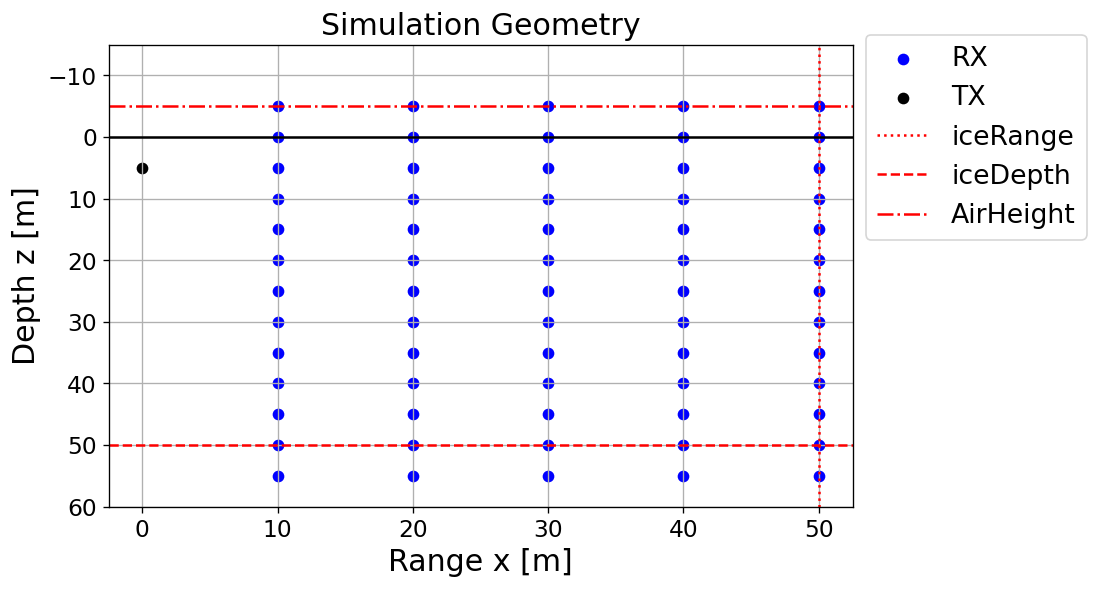

In [27]:
# Plot Simulation Geometry
rxList = sim_reader.rxList

fig = pl.figure(figsize=(8,5),dpi=120)
ax = fig.add_subplot(111)
ax.set_title('Simulation Geometry',fontsize=fontsize)
ax.scatter(rxList[:,0], rxList[:,1],c='b',label='RX')
ax.scatter(sim_reader.sourceRange, sim_reader.sourceDepth,c='k',label='TX')
ax.axvline(sim_reader.iceRange,linestyle=':',c='r',label='iceRange')
ax.axhline(sim_reader.iceDepth,linestyle='--',c='r',label='iceDepth')
ax.axhline(-1*sim_reader.airHeight,linestyle='dashdot',c='r',label='AirHeight')
ax.axhline(0,color='k')
ax.set_ylim(sim_reader.iceDepth+10, -1*sim_reader.airHeight -10)
ax.grid()
ax.set_xlabel('Range x [m]',fontsize=fontsize)
ax.set_ylabel('Depth z [m]',fontsize=fontsize)
ax.legend(fontsize=labelsize,loc='upper left', bbox_to_anchor=(1., 1.05))
ax.tick_params(axis='both',labelsize=labelsize-2)
pl.show()

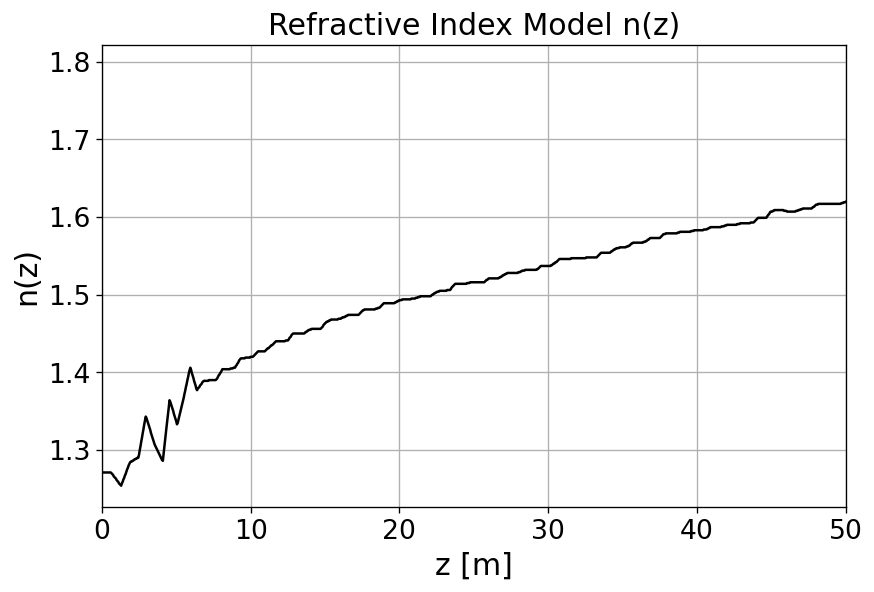

In [28]:
# Plot Ref. Index Prof.
z_prof = sim_reader.zProfile
n_prof = sim_reader.nProfile

fig = pl.figure(figsize=(8,5),dpi=120)
ax = fig.add_subplot(111)
ax.set_title('Refractive Index Model n(z)',fontsize=fontsize)
ax.plot(z_prof, n_prof, c='k')
ax.grid()
ax.set_xlabel('z [m]', fontsize=fontsize)
ax.set_ylabel('n(z)', fontsize=fontsize)
ax.tick_params(axis='both', labelsize=labelsize)
ax.set_xlim(0, sim_reader.iceDepth)
pl.show()

Actual RX positions 30.0 10.0


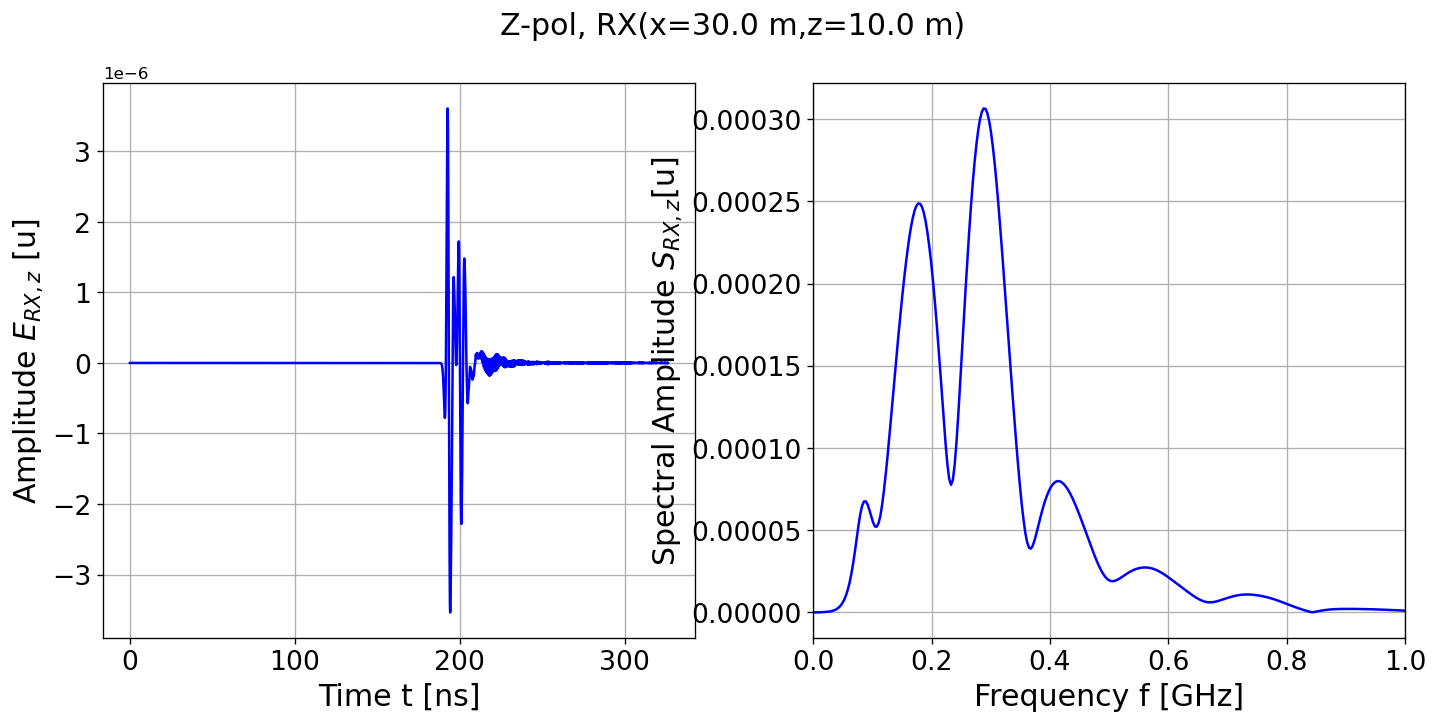

In [32]:
# Plot a RX Pulse (z pol)
x_rx = 30
z_rx = 10

x_rx_actual, z_rx_actual = sim_reader.get_rx_actual(x_rx=x_rx, z_rx=z_rx)
print('Actual RX positions', x_rx_actual, z_rx_actual)
tspace = sim_reader.tspace_rx
rx_pulse_z_ex = sim_reader.get_rx_pulse_z(x_rx=x_rx, z_rx=z_rx)
rx_spec_z_ex = sim_reader.get_rx_spec_z(x_rx=x_rx, z_rx=z_rx)
fspace = sim_reader.fspace

fig = pl.figure(figsize=(14,6),dpi=120)
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
ax_l = [ax1, ax2]
fig.suptitle(f'Z-pol, RX(x={x_rx_actual} m,z={z_rx_actual} m)',fontsize=fontsize)
ax1.plot(tspace, rx_pulse_z_ex, c='b')
ax2.plot(fspace, abs(rx_spec_z_ex), c='b')

ax1.set_ylabel('Amplitude $E_{RX,z}$ [u]',fontsize=fontsize)
ax1.set_xlabel('Time t [ns]',fontsize=fontsize)

ax2.set_ylabel('Spectral Amplitude $S_{RX,z} $[u]',fontsize=fontsize)
ax2.set_xlabel('Frequency f [GHz]',fontsize=fontsize)
ax2.set_xlim(0, 1)

for i in range(len(ax_l)):
    ax_l[i].grid()
    ax_l[i].tick_params(axis='both',labelsize=labelsize)
pl.show()